In [ ]:
# نصب پیش‌نیازها
!pip install pyyaml==5.1
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.2/274.2 kB 5.5 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
Looking in indexes: https://download.pytorch.org/whl/cu118


In [ ]:
# نصب مستقیم Detectron2 از گیت‌هاب
!python -m pip install 'git+https://github.com/facebookresearch/detectron2.git'

# وارد کردن کتابخانه‌ها برای تست نصب
import torch
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger() # فعال‌سازی لاگ‌های Detectron2

print(f"PyTorch Version: {torch.__version__}")
print(f"Detectron2 is successfully installed!")

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-4exqcg0q
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-4exqcg0q
  Resolved https://github.com/facebookresearch/detectron2.git to commit a2f4a8771ab77e8411c26b27f24f9489a28a2453
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.8/155.8 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.8/269.8 kB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 8.4 MB/s eta 0:00:00
  Created wheel for dete

In [ ]:
import os
import json

# ۱. تنظیم اتوماتیک کلید کگل شما در کولب
# Credentials are read from local ~/.kaggle/kaggle.json

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)
with open(os.path.join(kaggle_dir, "kaggle.json"), "w") as f:
    json.dump(kaggle_credentials, f)
os.chmod(os.path.join(kaggle_dir, "kaggle.json"), 0o600)

# ۲. نصب kagglehub و دانلود دیتاست
!pip install kagglehub -q
import kagglehub

print("🚀 در حال دانلود دیتاست از کگل به سرور گوگل کولب...")
dataset_path = kagglehub.dataset_download("norbertelter/pcb-defect-dataset")
print("\n✅ دانلود با موفقیت تمام شد!")
print("📁 آدرس دیتاست روی هارد کولب:", dataset_path)

🚀 در حال دانلود دیتاست از کگل به سرور گوگل کولب...


100%|██████████| 1.10G/1.10G [00:17<00:00, 67.5MB/s]

Extracting files...



✅ دانلود با موفقیت تمام شد!
📁 آدرس دیتاست روی هارد کولب: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2


In [ ]:
import os
import json
import cv2
from pathlib import Path
from tqdm import tqdm

print("🔍 در حال جستجوی خودکار مسیر دیتاست در سیستم کولب...")

# ۱. جستجوی خودکار پوشه train/images در کل هارد کولب
found_train_dirs = list(Path("/root/.cache").rglob("train/images")) + list(Path("/content").rglob("train/images"))

if not found_train_dirs:
    # اگر ساختار train/images نبود، دنبال هر پوشه‌ای به اسم train می‌گردد
    found_train_dirs = list(Path("/root/.cache").rglob("train")) + list(Path("/content").rglob("train"))

if not found_train_dirs:
    print("❌ هیچ فایلی پیدا نشد! احتمالاً دیتاست هنوز دانلود نشده یا پاک شده است.")
else:
    # پیدا کردن پوشه اصلی دیتاست
    actual_train_img_dir = found_train_dirs[0]

    # اگر داخل train/images بود، دو مرحله برمی‌گردیم عقب تا به ریشه برسیم
    if actual_train_img_dir.name == "images":
        dataset_root = actual_train_img_dir.parent.parent
    else:
        dataset_root = actual_train_img_dir.parent

    print(f"🎯 مسیر واقعی دیتاست با موفقیت پیدا شد:\n👉 {dataset_root}\n")

    # ۲. کلاس‌های دقیق
    CLASSES = [
        "mouse_bite",       # Index 0
        "spur",             # Index 1
        "missing_hole",     # Index 2
        "short",            # Index 3
        "open_circuit",     # Index 4
        "spurious_copper"   # Index 5
    ]

    # ۳. تابع تبدیل
    def convert_yolo_to_coco(images_dir, labels_dir, output_json_path):
        coco_format = {
            "images": [],
            "annotations": [],
            "categories": [{"id": i, "name": name} for i, name in enumerate(CLASSES)]
        }

        image_paths = list(Path(images_dir).glob("*.jpg")) + list(Path(images_dir).glob("*.png"))

        if not image_paths:
            print(f"⚠️ تصویری در {images_dir} پیدا نشد!")
            return

        ann_id = 0
        print(f"⏳ در حال تبدیل {len(image_paths)} تصویر از: {images_dir}")

        for img_id, img_path in enumerate(tqdm(image_paths)):
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            height, width, _ = img.shape

            coco_format["images"].append({
                "id": img_id,
                "file_name": img_path.name,
                "width": width,
                "height": height
            })

            txt_path = Path(labels_dir) / (img_path.stem + ".txt")
            if txt_path.exists():
                with open(txt_path, "r") as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            class_id = int(parts[0])
                            x_center, y_center, bw, bh = map(float, parts[1:5])

                            abs_w = bw * width
                            abs_h = bh * height
                            abs_x = (x_center * width) - (abs_w / 2.0)
                            abs_y = (y_center * height) - (abs_h / 2.0)

                            coco_format["annotations"].append({
                                "id": ann_id,
                                "image_id": img_id,
                                "category_id": class_id,
                                "bbox": [abs_x, abs_y, abs_w, abs_h],
                                "area": abs_w * abs_h,
                                "iscrowd": 0
                            })
                            ann_id += 1

        with open(output_json_path, "w", encoding="utf-8") as f:
            json.dump(coco_format, f)

        print(f"✅ فایل {output_json_path} ساخته شد (عکس‌ها: {len(coco_format['images'])}, لیبل‌ها: {len(coco_format['annotations'])})\n")

    # مسیرهای نهایی
    train_images = os.path.join(dataset_root, "train", "images")
    train_labels = os.path.join(dataset_root, "train", "labels")

    val_images = os.path.join(dataset_root, "val", "images")
    val_labels = os.path.join(dataset_root, "val", "labels")

    test_images = os.path.join(dataset_root, "test", "images")
    test_labels = os.path.join(dataset_root, "test", "labels")

    # اجرای تبدیل
    convert_yolo_to_coco(train_images, train_labels, "/content/train_coco.json")
    convert_yolo_to_coco(val_images, val_labels, "/content/val_coco.json")
    convert_yolo_to_coco(test_images, test_labels, "/content/test_coco.json")

🔍 در حال جستجوی خودکار مسیر دیتاست در سیستم کولب...
🎯 مسیر واقعی دیتاست با موفقیت پیدا شد:
👉 /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2/pcb-defect-dataset

⏳ در حال تبدیل 8534 تصویر از: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2/pcb-defect-dataset/train/images


100%|██████████| 8534/8534 [00:32<00:00, 259.19it/s]


✅ فایل /content/train_coco.json ساخته شد (عکس‌ها: 8534, لیبل‌ها: 12991)

⏳ در حال تبدیل 1066 تصویر از: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2/pcb-defect-dataset/val/images


100%|██████████| 1066/1066 [00:03<00:00, 298.35it/s]


✅ فایل /content/val_coco.json ساخته شد (عکس‌ها: 1066, لیبل‌ها: 1595)

⏳ در حال تبدیل 1068 تصویر از: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2/pcb-defect-dataset/test/images


100%|██████████| 1068/1068 [00:02<00:00, 377.09it/s]

✅ فایل /content/test_coco.json ساخته شد (عکس‌ها: 1068, لیبل‌ها: 1662)



WARNING [08/19 12:30:28 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[08/19 12:30:28 d2.data.datasets.coco]: Loaded 8534 images in COCO format from /content/train_coco.json


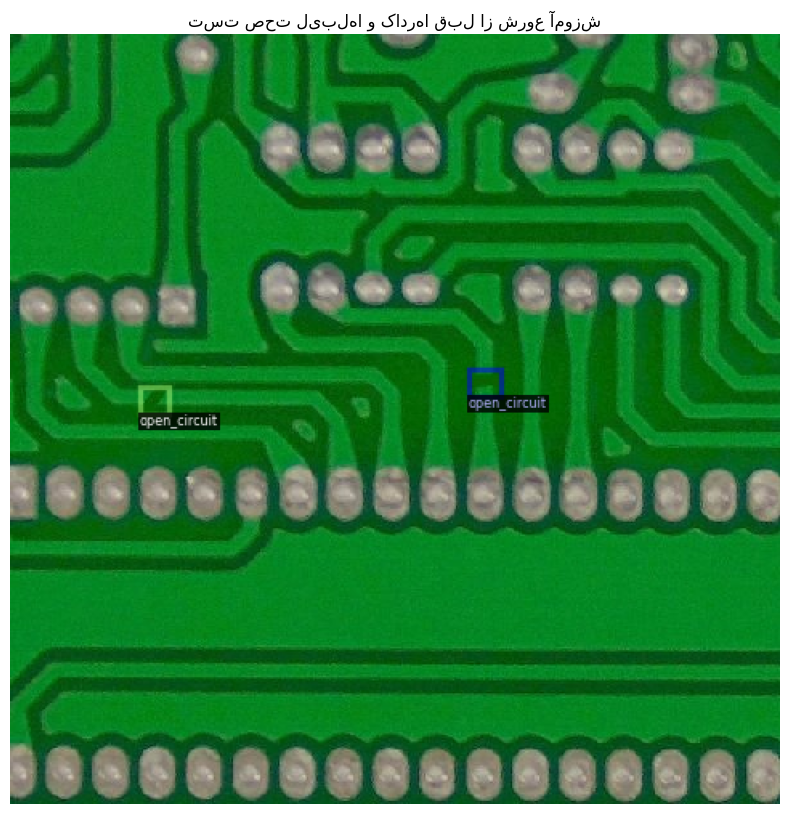

✅ تعداد تصاویر آموزش: 8534
✅ کلاس‌های فعال: ['mouse_bite', 'spur', 'missing_hole', 'short', 'open_circuit', 'spurious_copper']


In [ ]:
import cv2
import random
import matplotlib.pyplot as plt
from detectron2.data.datasets import register_coco_instances
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.utils.visualizer import Visualizer

# ۱. پاک کردن ثبتهای قبلی در صورت وجود (برای جلوگیری از ارور ثبت تکراری)
for d in ["pcb_train", "pcb_val", "pcb_test"]:
    if d in DatasetCatalog.list():
        DatasetCatalog.remove(d)
        MetadataCatalog.remove(d)

# ۲. ثبت دیتاست‌های آموزش، اعتبارسنجی و تست
register_coco_instances("pcb_train", {}, "/content/train_coco.json", train_images)
register_coco_instances("pcb_val", {}, "/content/val_coco.json", val_images)
register_coco_instances("pcb_test", {}, "/content/test_coco.json", test_images)

# ۳. بررسی سلامت دیتاست
metadata = MetadataCatalog.get("pcb_train")
dataset_dicts = DatasetCatalog.get("pcb_train")

# انتخاب یک تصویر تصادفی و رسم کادرهای واقعی (Ground Truth)
sample = random.choice(dataset_dicts)
img = cv2.imread(sample["file_name"])
visualizer = Visualizer(img[:, :, ::-1], metadata=metadata, scale=0.8)
out = visualizer.draw_dataset_dict(sample)

plt.figure(figsize=(10, 10))
plt.imshow(out.get_image())
plt.axis("off")
plt.title("تست صحت لیبل‌ها و کادرها قبل از شروع آموزش")
plt.show()

print(f"✅ تعداد تصاویر آموزش: {len(dataset_dicts)}")
print(f"✅ کلاس‌های فعال: {metadata.get('thing_classes')}")

In [ ]:
import os
from google.colab import drive
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2 import model_zoo

# ۱. متصل کردن گوگل درایو به کولب
print("📂 در حال اتصال به گوگل درایو...")
drive.mount('/content/drive')

📂 در حال اتصال به گوگل درایو...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ۲. ایجاد پوشه اختصاصی در گوگل درایو برای ذخیره خروجی‌ها
drive_output_dir = "/content/drive/MyDrive/Detectron2_PCB_Project"
os.makedirs(drive_output_dir, exist_ok=True)
print(f"✅ مسیر ذخیره‌سازی در درایو: {drive_output_dir}")

✅ مسیر ذخیره‌سازی در درایو: /content/drive/MyDrive/Detectron2_PCB_Project


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2 import model_zoo

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))

cfg.DATASETS.TRAIN = ("pcb_train",)
cfg.DATASETS.TEST = ("pcb_val",)

# تنظیم تعداد ورکرها دقیقا برابر هسته‌های CPU سیستم
cfg.DATALOADER.NUM_WORKERS = os.cpu_count()

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")

# 🚀 ۱. بچ‌سایز ۱۶ (پر کردن بهینه حافظه گرافیک)
cfg.SOLVER.IMS_PER_BATCH = 16

# 🚀 ۲. دو برابر کردن نرخ یادگیری متناسب با بچ ۱۶
cfg.SOLVER.BASE_LR = 0.002

# 🚀 ۳. تعداد تکرارها برای ۱۰ ایپاک کامل: ۵۳۳۴ مرحله
# فرمول: (8534 / 16) * 10
cfg.SOLVER.MAX_ITER = 5334

# 🚀 ۴. تنظیم شروع ملایم (Warmup) برای ۴۰۰ مرحله اول
cfg.SOLVER.WARMUP_ITERS = 400

# 🚀 ۵. کاهش نرخ یادگیری در ایپاک ۷ و ۹
cfg.SOLVER.STEPS = (3734, 4800)
cfg.SOLVER.GAMMA = 0.1

# 🚀 ۶. شتاب‌دهنده سرعت FP16
cfg.SOLVER.AMP.ENABLED = True

# ۷. ذخیره چک‌پوینت در پایان هر ۱ ایپاک (هر ۵۳۴ تکرار در گوگل درایو)
cfg.SOLVER.CHECKPOINT_PERIOD = 534

cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 6

cfg.OUTPUT_DIR = "/content/drive/MyDrive/Detectron2_PCB_Project"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("🏎️ گاز نهایی! شروع آموزش فوق‌سریع ۱۰ ایپاک با بچ‌سایز ۱۶...")
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

🏎️ گاز نهایی! شروع آموزش فوق‌سریع ۱۰ ایپاک با بچ‌سایز ۱۶...
[08/19 12:46:16 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNor

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}


[08/19 12:46:16 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/detectron2/engine/hooks.py:359: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.scheduler.step()


[08/19 12:46:46 d2.utils.events]:  eta: 2:04:56  iter: 19  total_loss: 2.088  loss_cls: 1.689  loss_box_reg: 0.02096  loss_rpn_cls: 0.3637  loss_rpn_loc: 0.02434    time: 1.4523  last_time: 1.4121  data_time: 0.3241  last_data_time: 0.2596   lr: 9.6905e-05  max_mem: 8545M
[08/19 12:47:15 d2.utils.events]:  eta: 2:04:20  iter: 39  total_loss: 0.6  loss_cls: 0.2466  loss_box_reg: 0.04097  loss_rpn_cls: 0.2631  loss_rpn_loc: 0.02718    time: 1.4494  last_time: 1.3526  data_time: 0.3208  last_data_time: 0.2473   lr: 0.00019681  max_mem: 8545M
[08/19 12:47:44 d2.utils.events]:  eta: 2:02:58  iter: 59  total_loss: 0.4209  loss_cls: 0.1988  loss_box_reg: 0.05706  loss_rpn_cls: 0.1263  loss_rpn_loc: 0.02507    time: 1.4503  last_time: 1.3747  data_time: 0.3376  last_data_time: 0.2620   lr: 0.00029671  max_mem: 8546M
[08/19 12:48:12 d2.utils.events]:  eta: 2:02:19  iter: 79  total_loss: 0.4818  loss_cls: 0.2549  loss_box_reg: 0.107  loss_rpn_cls: 0.09077  loss_rpn_loc: 0.01978    time: 1.4481  

[08/19 14:53:23 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Detectron2_PCB_Project/model_final.pth ...
WARNING [08/19 14:53:24 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[08/19 14:53:24 d2.data.datasets.coco]: Loaded 1068 images in COCO format from /content/test_coco.json
✅ مدل با موفقیت از مسیر درایو بارگذاری شد.
📁 تعداد کل تصاویر موجود در دیتای Test: 1068

📊 در حال ارزیابی دقت مدل روی تمام تصاویر تست (محاسبه mAP)...
WARNING [08/19 14:53:24 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[08/19 14:53:24 d2.data.datasets.coco]: Loaded 1068 images in COCO format from /content/test_coco.json
[08/19 14:53:24 d2.data.build]: Distribution of instances among all 6 categories:
|  category  | #instances   |   category   | #instances   |   category    | #instances   |
|:----------:|:-------------|:----------

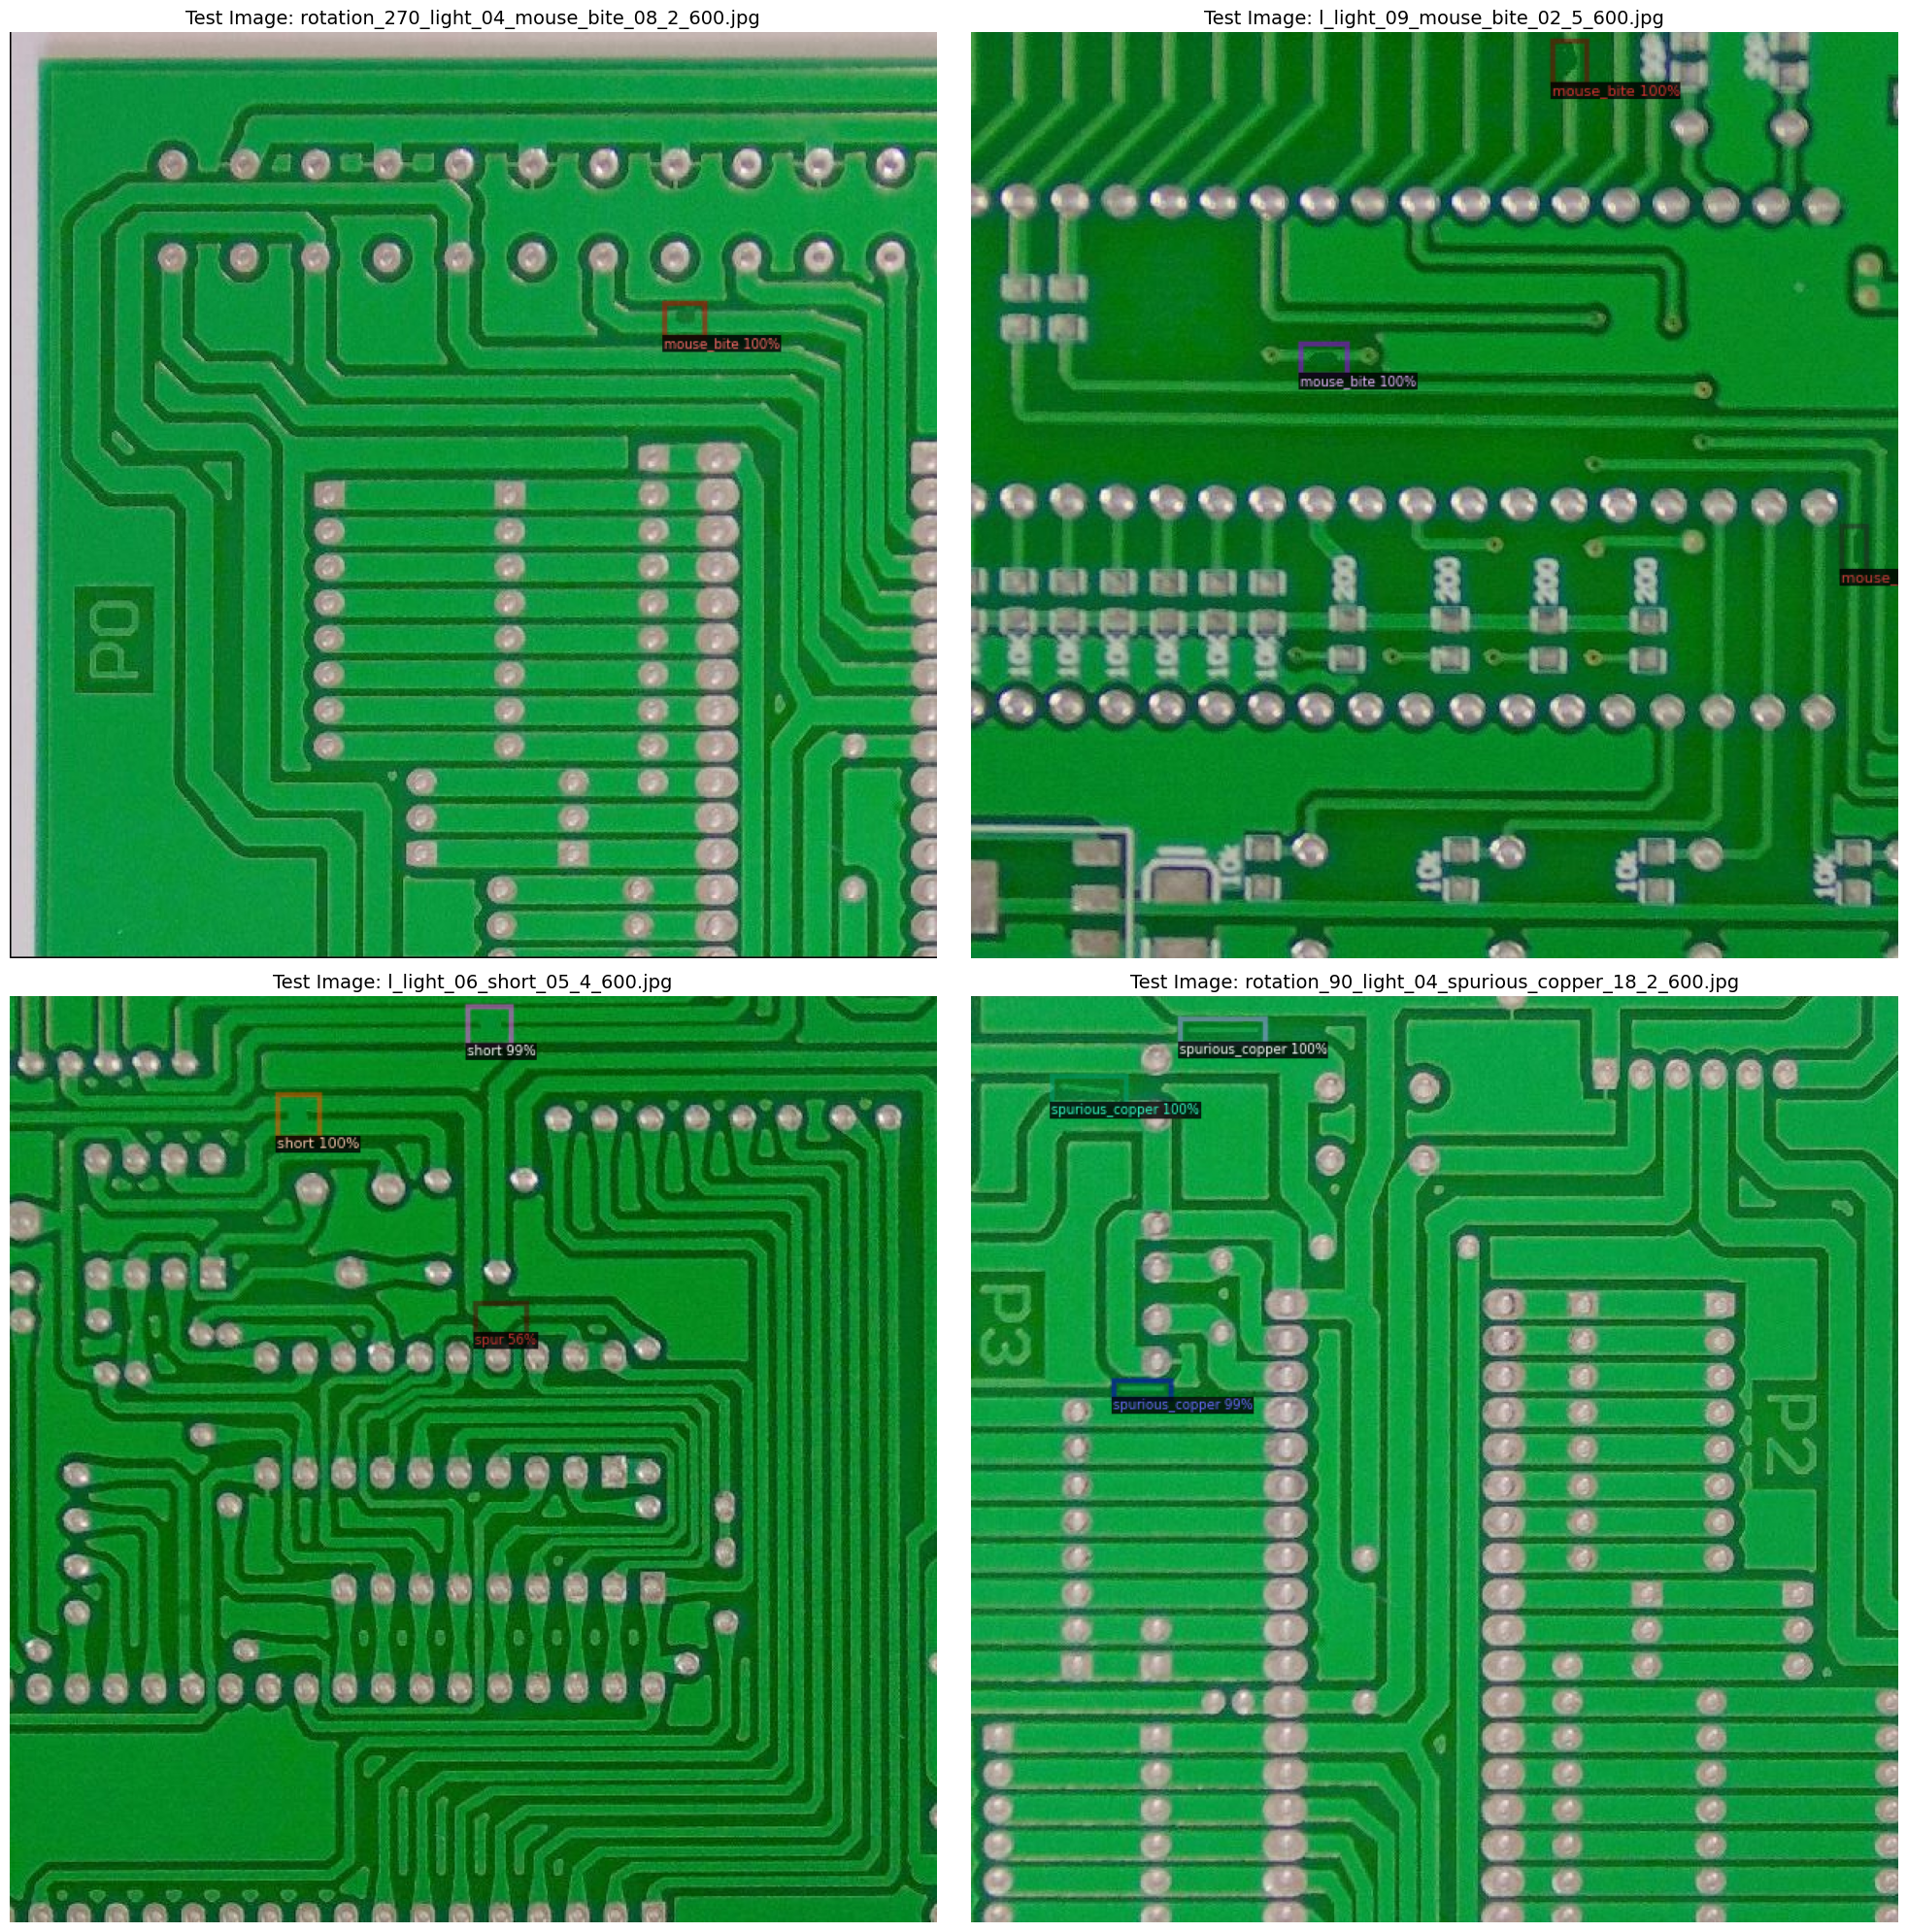

In [ ]:
import os
import cv2
import random
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

# ۱. بارگذاری کانفیگ و وزن‌های آموزش‌دیده از گوگل درایو
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 6
cfg.OUTPUT_DIR = "/content/drive/MyDrive/Detectron2_PCB_Project"

# اتصال به فایل وزن نهایی
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")

# تعیین آستانه اطمینان (فقط پیش‌بینی‌های با اطمینان بالای ۵۰٪ رسم شوند)
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.50

predictor = DefaultPredictor(cfg)
test_metadata = MetadataCatalog.get("pcb_test")
test_dicts = DatasetCatalog.get("pcb_test")

print(f"✅ مدل با موفقیت از مسیر درایو بارگذاری شد.")
print(f"📁 تعداد کل تصاویر موجود در دیتای Test: {len(test_dicts)}\n")

# ==========================================
# بخش اول: محاسبه جدول متریک‌های رسمی COCO (mAP)
# ==========================================
print("📊 در حال ارزیابی دقت مدل روی تمام تصاویر تست (محاسبه mAP)...")
evaluator = COCOEvaluator("pcb_test", output_dir=cfg.OUTPUT_DIR)
test_loader = build_detection_test_loader(cfg, "pcb_test")
eval_results = inference_on_dataset(predictor.model, test_loader, evaluator)

# ==========================================
# بخش دوم: تست چشمی روی ۴ تصویر تصادفی از Test
# ==========================================
print("\n🖼️ در حال رسم پیش‌بینی‌های مدل روی ۴ نمونه تصادفی از دیتای تست...")

num_samples = 4
samples = random.sample(test_dicts, num_samples)

plt.figure(figsize=(20, 20))

for i, d in enumerate(samples):
    im = cv2.imread(d["file_name"])
    outputs = predictor(im)

    # رسم کادرهای پیش‌بینی شده توسط مدل
    v = Visualizer(im[:, :, ::-1], metadata=test_metadata, scale=1.0)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    plt.subplot(2, 2, i + 1)
    plt.imshow(out.get_image())
    plt.axis("off")
    plt.title(f"Test Image: {os.path.basename(d['file_name'])}", fontsize=14)

plt.tight_layout()
plt.show()